# 1. Import Library

In [21]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

Tahap pertama adalah mengimpor library yang dibutuhkan, seperti Pandas untuk mengolah dataset, NumPy untuk operasi numerik, Matplotlib dan Seaborn untuk visualisasi, serta Scikit-learn untuk preprocessing, pelatihan model, dan evaluasi. Library tersebut mendukung seluruh proses klasifikasi laptop.

# 2. Membaca Dataset

In [22]:
df = pd.read_csv("laptop.csv")

print("Jumlah data:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

display(df.head())

Jumlah data: 3976
Jumlah kolom: 18


,Unnamed: 0,Brand,Name,Price,Processor_Name,Processor_Brand,RAM_Expandable,RAM,RAM_TYPE,Ghz,Display_type,Display,GPU,GPU_Brand,SSD,HDD,Adapter,Battery_Life
0,0,HP,HP Chromebook 11A-NA0002MU (2E4N0PA) Laptop (1...,22990,MediaTek Octa-core,MediaTek,Not Expandable,4 GB,DDR4 RAM,2.0 Ghz Processor,LED,11.6,Integrated Graphics,MediaTek,64 GB SSD Storage,No HDD,45,Upto 12 Hrs Battery Life
1,1,Lenovo,Lenovo Ideapad Slim 3 (82KU017KIN) Laptop (15....,36289,AMD Hexa-Core Ryzen 5,AMD,12 GB Expandable,8 GB,DDR4 RAM,4.0 Ghz Processor,LCD,15.6,Radeon,AMD,512 GB SSD Storage,No HDD,65,Upto 11 Hrs Battery Life
2,3,Dell,Dell G15-5520 (D560822WIN9B) Laptop (15.6 Inch...,78500,Intel Core i5 (12th Gen),Intel,32 GB Expandable,16 GB,DDR5 RAM,3.3 Ghz Processor,LCD,15.6,"GeForce RTX 3050 GPU, 4 GB",NVIDIA,512 GB SSD Storage,No HDD,56,Upto 10 Hrs Battery Life
3,4,HP,HP 15s-fy5007TU (91R03PA) Laptop (15.6 Inch | ...,55490,Intel Core i5 (12th Gen),Intel,8 GB Expandable,8 GB,DDR4 RAM,4.2 Ghz Processor,LCD,15.6,Iris Xe,Intel,512 GB SSD Storage,No HDD,no,Upto 7.30 Hrs Battery Life
4,6,Infinix,Infinix Inbook Y2 Plus XL29 Laptop (15.6 Inch ...,21990,Intel Core i3 (11th Gen),Intel,Not Expandable,8 GB LP,LPDDR4X RAM,1.7 Ghz Processor,LCD,15.6,UHD,Intel,512 GB SSD Storage,No HDD,45,Upto 8 Hrs Battery Life


Pada tahap ini, program membaca file laptop.csv menggunakan Pandas. Dataset kemudian ditampilkan untuk melihat beberapa baris pertama serta mengetahui jumlah baris dan kolom yang tersedia. Tahap ini bertujuan memastikan dataset berhasil dibaca dan memberikan gambaran awal mengenai atribut laptop yang akan digunakan dalam proses klasifikasi.

# 3. Memeriksa Dataset

In [23]:
print("Informasi Dataset:\n")
df.info()

print("\nJumlah Missing Values:")
print(df.isnull().sum())

print("\nStatistik Dataset:")
display(df.describe(include="all"))

Informasi Dataset:

<class 'pandas.DataFrame'>
RangeIndex: 3976 entries, 0 to 3975
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Unnamed: 0       3976 non-null   int64
 1   Brand            3976 non-null   str  
 2   Name             3976 non-null   str  
 3   Price            3976 non-null   int64
 4   Processor_Name   3976 non-null   str  
 5   Processor_Brand  3976 non-null   str  
 6   RAM_Expandable   3976 non-null   str  
 7   RAM              3976 non-null   str  
 8   RAM_TYPE         3976 non-null   str  
 9   Ghz              3976 non-null   str  
 10  Display_type     3976 non-null   str  
 11  Display          3976 non-null   str  
 12  GPU              3968 non-null   str  
 13  GPU_Brand        3972 non-null   str  
 14  SSD              3976 non-null   str  
 15  HDD              3976 non-null   str  
 16  Adapter          3976 non-null   str  
 17  Battery_Life     3558 non-null   str  
dtyp

,Unnamed: 0,Brand,Name,Price,Processor_Name,Processor_Brand,RAM_Expandable,RAM,RAM_TYPE,Ghz,Display_type,Display,GPU,GPU_Brand,SSD,HDD,Adapter,Battery_Life
count,3976.000000,3976,3976,3976.000000,3976,3976,3976,3976,3976,3976,3976,3976,3968,3972,3976,3976,3976,3558
unique,NaN,31,3941,NaN,125,19,10,20,19,31,2,34,300,11,19,8,68,191
top,NaN,ASUS,Lenovo Ideapad 3 15ITL6 (82H801L7IN) Laptop (1...,NaN,Intel Core i5 (11th Gen),Intel,Not Expandable,8 GB,DDR4 RAM,4.2 Ghz Processor,LCD,15.6,UHD,Intel,512 GB SSD Storage,No HDD,65,65W Adapter
freq,NaN,989,2,NaN,316,3009,2157,1608,1505,331,2034,2205,651,1939,1931,3014,1458,803
mean,2181.495724,NaN,NaN,72432.528672,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,1297.029657,NaN,NaN,52207.650948,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,NaN,NaN,7990.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,1058.750000,NaN,NaN,39873.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,2098.500000,NaN,NaN,58990.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,3342.250000,NaN,NaN,84990.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Tahap ini dilakukan untuk mengetahui struktur dataset, tipe data pada setiap kolom, jumlah nilai yang kosong (missing values), serta ringkasan statistik data. Pemeriksaan tersebut penting untuk mengidentifikasi masalah pada dataset sebelum proses pengolahan dilakukan, sehingga data yang digunakan dapat dipersiapkan dengan lebih baik.

# 4. Membersihkan dan Mengolah Data

In [24]:
# Menghapus baris duplikat
df = df.drop_duplicates().copy()

# Mengubah harga menjadi numerik
df["Price"] = pd.to_numeric(df["Price"], errors="coerce")

# Mengambil kapasitas RAM dalam GB
df["RAM_GB"] = pd.to_numeric(
    df["RAM"].astype(str).str.extract(r"(\d+(?:\.\d+)?)")[0],
    errors="coerce"
)

# Mengambil kapasitas SSD dalam GB
df["SSD_GB"] = pd.to_numeric(
    df["SSD"].astype(str).str.extract(r"(\d+(?:\.\d+)?)")[0],
    errors="coerce"
)

# Jika tidak ada SSD, kapasitas SSD dianggap 0
df.loc[
    df["SSD"].astype(str).str.contains("NO SSD", case=False, na=False),
    "SSD_GB"
] = 0

# Mengambil kecepatan prosesor dalam GHz
df["CPU_GHz"] = pd.to_numeric(
    df["Ghz"].astype(str).str.extract(r"(\d+(?:\.\d+)?)")[0],
    errors="coerce"
)

# Mengambil ukuran layar
df["Display_Inch"] = pd.to_numeric(
    df["Display"].astype(str).str.extract(r"(\d+(?:\.\d+)?)")[0],
    errors="coerce"
)

# Mengambil kapasitas HDD jika tersedia
df["HDD_GB"] = pd.to_numeric(
    df["HDD"].astype(str).str.extract(r"(\d+(?:\.\d+)?)")[0],
    errors="coerce"
)

df["HDD_GB"] = df["HDD_GB"].fillna(0)

# Menghapus data yang tidak memiliki harga
df = df.dropna(subset=["Price"])

print("Data setelah dibersihkan:", df.shape)

display(
    df[
        [
            "Price",
            "RAM",
            "RAM_GB",
            "SSD",
            "SSD_GB",
            "CPU_GHz",
            "Display_Inch"
        ]
    ].head()
)

Data setelah dibersihkan: (3976, 23)


,Price,RAM,RAM_GB,SSD,SSD_GB,CPU_GHz,Display_Inch
0,22990,4 GB,4,64 GB SSD Storage,64.0,2.0,11.6
1,36289,8 GB,8,512 GB SSD Storage,512.0,4.0,15.6
2,78500,16 GB,16,512 GB SSD Storage,512.0,3.3,15.6
3,55490,8 GB,8,512 GB SSD Storage,512.0,4.2,15.6
4,21990,8 GB LP,8,512 GB SSD Storage,512.0,1.7,15.6


Pada tahap ini, program menghapus data duplikat dan mengubah beberapa atribut spesifikasi laptop menjadi format numerik. Atribut yang diolah meliputi RAM, SSD, HDD, kecepatan prosesor, dan ukuran layar. Pengolahan ini diperlukan agar informasi spesifikasi dapat digunakan oleh algoritma SVM. Data yang memiliki harga kosong juga dihapus, sedangkan nilai kosong pada fitur lainnya akan ditangani pada tahap preprocessing berikutnya.

# 5. Membuat Label Klasifikasi

In [25]:
def tentukan_kategori(row):
    harga = row["Price"]
    ram = row["RAM_GB"] if pd.notna(row["RAM_GB"]) else 0
    gpu = str(row["GPU"]).lower()
    processor = str(row["Processor_Name"]).lower()

    # Kategori High End
    if (
        harga >= 100000
        or "geforce rtx" in gpu
        or "radeon rx" in gpu
        or (
            harga >= 70000
            and ram >= 16
            and ("core i7" in processor or "ryzen 7" in processor
                 or "core i9" in processor or "ryzen 9" in processor)
        )
    ):
        return "High End"

    # Kategori Entry Level
    elif harga < 50000 and ram < 16:
        return "Entry Level"

    # Kategori Mid Level
    else:
        return "Mid Level"


df["Kategori"] = df.apply(tentukan_kategori, axis=1)

print("Jumlah masing-masing kategori:")
print(df["Kategori"].value_counts())

display(df[["Brand", "Price", "RAM", "GPU", "Kategori"]].head(10))

Jumlah masing-masing kategori:
Kategori
Entry Level    1483
High End       1281
Mid Level      1212
Name: count, dtype: int64


,Brand,Price,RAM,GPU,Kategori
0,HP,22990,4 GB,Integrated Graphics,Entry Level
1,Lenovo,36289,8 GB,Radeon,Entry Level
2,Dell,78500,16 GB,"GeForce RTX 3050 GPU, 4 GB",High End
3,HP,55490,8 GB,Iris Xe,Mid Level
4,Infinix,21990,8 GB LP,UHD,Entry Level
5,Acer,34990,16 GB,Iris Xe,Mid Level
6,HP,49599,8 GB,Radeon,Entry Level
7,Acer,39990,8 GB,Iris Xe,Entry Level
8,Lenovo,33111,4 GB,UHD 620,Entry Level
9,ASUS,48990,8 GB,"GeForce RTX 2050 GPU, 4 GB",High End


Dataset awal belum memiliki kolom kategori laptop. Oleh karena itu, program membuat kolom baru bernama Kategori yang membagi laptop menjadi tiga kelas, yaitu Entry Level, Mid Level, dan High End. Penentuan kategori dilakukan berdasarkan aturan yang mempertimbangkan harga, RAM, dan karakteristik GPU serta prosesor tertentu. Label ini nantinya menjadi target yang dipelajari oleh model SVM. Aturan yang digunakan merupakan asumsi awal untuk kebutuhan klasifikasi dan bukan standar resmi kategori laptop.

# 6. Visualisasi Distribusi Kategori

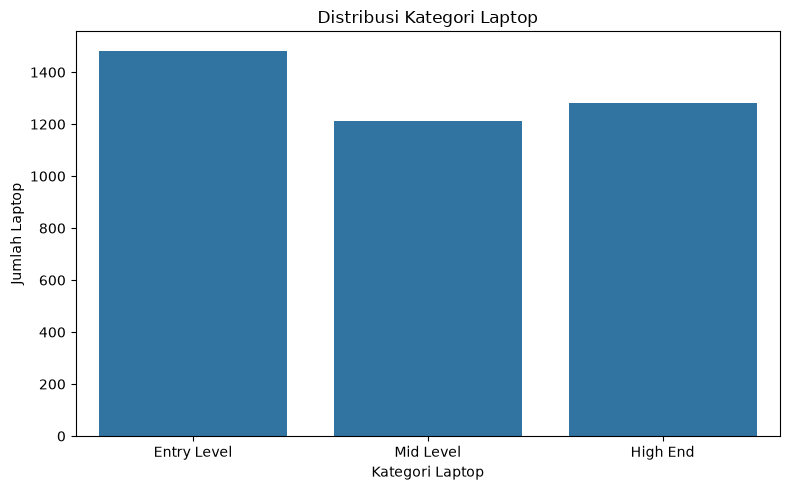

In [26]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Kategori",
    order=["Entry Level", "Mid Level", "High End"]
)

plt.title("Distribusi Kategori Laptop")
plt.xlabel("Kategori Laptop")
plt.ylabel("Jumlah Laptop")
plt.tight_layout()
plt.show()

Pada tahap ini, program menampilkan grafik jumlah laptop untuk setiap kategori. Grafik tersebut membantu mengetahui distribusi data pada kelas Entry Level, Mid Level, dan High End. Jika terdapat perbedaan jumlah yang besar antarkategori, kondisi tersebut perlu diperhatikan karena dapat memengaruhi hasil evaluasi model.

# 7. Menentukan Fitur Target

In [27]:
fitur_numerik = [
    "RAM_GB",
    "SSD_GB",
    "HDD_GB",
    "CPU_GHz",
    "Display_Inch"
]

fitur_kategorikal = [
    "Brand",
    "Processor_Name",
    "Processor_Brand",
    "RAM_TYPE",
    "GPU",
    "GPU_Brand",
    "Display_type"
]

fitur = fitur_numerik + fitur_kategorikal

X = df[fitur].copy()
y = df["Kategori"].copy()

print("Jumlah fitur:", len(fitur))
print("Jumlah data:", len(X))

print("\nDistribusi target:")
print(y.value_counts())

Jumlah fitur: 12
Jumlah data: 3976

Distribusi target:
Kategori
Entry Level    1483
High End       1281
Mid Level      1212
Name: count, dtype: int64


Tahap ini bertujuan menentukan atribut yang digunakan dalam proses klasifikasi. Variabel X berisi fitur spesifikasi laptop, seperti RAM, SSD, HDD, kecepatan prosesor, ukuran layar, merek, dan GPU. Sementara itu, variabel y berisi label kategori laptop yang akan diprediksi. Kolom harga tidak digunakan sebagai fitur karena telah menjadi salah satu dasar pembentukan label, sehingga penggunaannya kembali berpotensi menyebabkan data leakage.

# 8. Membagi Data Training dan Testing

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

Jumlah data training: 3180
Jumlah data testing: 796


Dataset dibagi menjadi 80% data training dan 20% data testing. Data training digunakan untuk melatih model agar dapat mempelajari pola hubungan antara spesifikasi dan kategori laptop. Sementara itu, data testing digunakan untuk menguji kemampuan model dalam memprediksi kategori pada data yang tidak digunakan selama pelatihan. Parameter stratify=y membantu menjaga proporsi setiap kategori pada kedua bagian data.

# 9. Preprocessing dan Pemodelan SVM

In [29]:
# Preprocessing fitur numerik
preprocessing_numerik = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing fitur kategorikal
preprocessing_kategorikal = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Menggabungkan preprocessing
preprocessor = ColumnTransformer([
    ("numerik", preprocessing_numerik, fitur_numerik),
    ("kategorikal", preprocessing_kategorikal, fitur_kategorikal)
])

# Membuat model SVM
model = Pipeline([
    ("preprocessing", preprocessor),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale"))
])

# Melatih model
model.fit(X_train, y_train)

print("Model SVM berhasil dilatih!")

Model SVM berhasil dilatih!


Pada tahap ini, data dipersiapkan sebelum digunakan untuk melatih model SVM. Fitur numerik diproses menggunakan StandardScaler agar memiliki skala yang sebanding, sedangkan fitur kategorikal diubah menjadi representasi numerik menggunakan OneHotEncoder. Nilai kosong ditangani dengan metode imputasi. Selanjutnya, model SVM dengan kernel RBF dilatih untuk mempelajari batas pemisah antara ketiga kategori laptop berdasarkan fitur yang tersedia.

# 10. Evaluasi Model

In [30]:
# Prediksi data testing
y_pred = model.predict(X_test)

# Menghitung akurasi
akurasi = accuracy_score(y_test, y_pred)

print("Akurasi Model SVM:", round(akurasi * 100, 2), "%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=["Entry Level", "Mid Level", "High End"],
        zero_division=0
    )
)

Akurasi Model SVM: 88.82 %

Classification Report:
              precision    recall  f1-score   support

 Entry Level       0.88      0.90      0.89       297
   Mid Level       0.83      0.80      0.82       243
    High End       0.95      0.95      0.95       256

    accuracy                           0.89       796
   macro avg       0.89      0.89      0.89       796
weighted avg       0.89      0.89      0.89       796



Setelah proses pelatihan selesai, model digunakan untuk memprediksi kategori pada data testing. Hasil prediksi kemudian dibandingkan dengan label aktual menggunakan beberapa metrik evaluasi, yaitu accuracy, precision, recall, dan F1-score. Accuracy menunjukkan persentase prediksi yang benar secara keseluruhan, precision mengukur ketepatan prediksi suatu kategori, recall mengukur kemampuan menemukan data dalam kategori tersebut, sedangkan F1-score merupakan gabungan precision dan recall.

# 11. Confusion Matrix

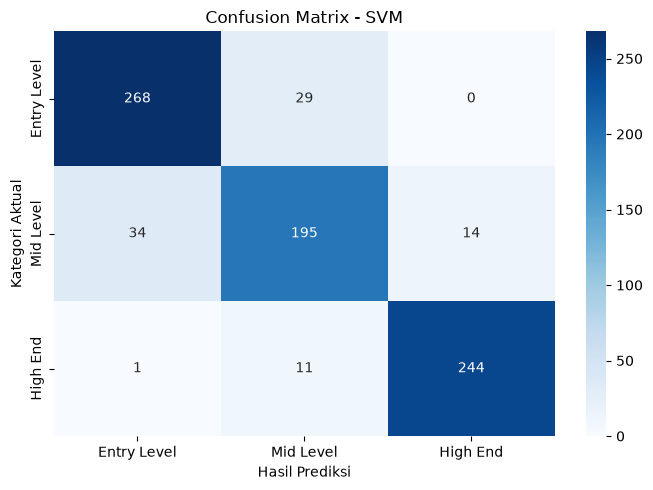

In [31]:
label_kategori = [
    "Entry Level",
    "Mid Level",
    "High End"
]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=label_kategori
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_kategori,
    yticklabels=label_kategori
)

plt.title("Confusion Matrix - SVM")
plt.xlabel("Hasil Prediksi")
plt.ylabel("Kategori Aktual")
plt.tight_layout()
plt.show()

Confusion matrix digunakan untuk melihat perbandingan antara kategori aktual dan kategori hasil prediksi model. Angka pada diagonal utama menunjukkan jumlah prediksi yang benar, sedangkan angka di luar diagonal menunjukkan jumlah kesalahan klasifikasi. Melalui visualisasi ini, dapat diketahui kategori mana yang berhasil diprediksi dengan baik dan kategori mana yang masih sering tertukar oleh model SVM.

# 12. Visualisasi Akurasi

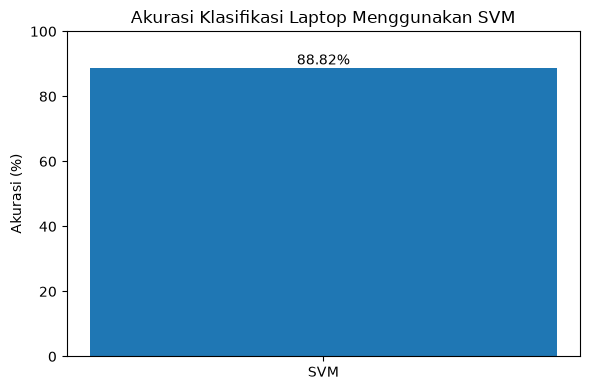

In [32]:
plt.figure(figsize=(6, 4))

plt.bar(
    ["SVM"],
    [akurasi * 100]
)

plt.ylim(0, 100)
plt.ylabel("Akurasi (%)")
plt.title("Akurasi Klasifikasi Laptop Menggunakan SVM")

plt.text(
    0,
    akurasi * 100 + 1,
    f"{akurasi * 100:.2f}%",
    ha="center"
)

plt.tight_layout()
plt.show()

Pada tahap ini, nilai akurasi model ditampilkan dalam bentuk grafik batang. Visualisasi tersebut mempermudah pembaca memahami persentase prediksi yang benar pada data testing. Semakin tinggi akurasi, semakin besar proporsi prediksi yang sesuai dengan label pengujian. Namun, akurasi yang tinggi tidak selalu berarti model mampu menentukan kualitas laptop secara objektif, terutama karena label kategori dibuat berdasarkan aturan awal.

# 13. Prediksi Kategori Laptop

In [33]:
hasil_uji = X_test.copy()

hasil_uji["Kategori_Aktual"] = y_test
hasil_uji["Kategori_Prediksi"] = y_pred

display(hasil_uji.head(5))

,RAM_GB,SSD_GB,HDD_GB,CPU_GHz,Display_Inch,Brand,Processor_Name,Processor_Brand,RAM_TYPE,GPU,GPU_Brand,Display_type,Kategori_Aktual,Kategori_Prediksi
2104,16,512.0,0.0,2.3,15.6,ASUS,Intel Core i7 (12th Gen),Intel,DDR5 RAM,"GeForce RTX 3050 Ti GPU, 4 GB",NVIDIA,LCD,High End,High End
1397,8,512.0,0.0,2.4,14.0,ASUS,Intel Core i5 (11th Gen),Intel,LPDDR4X RAM,Iris Xe,Intel,LED,Mid Level,Mid Level
3502,4,0.0,500.0,1.4,15.6,HP,AMD Dual-Core E1 APU,AMD,DDR3 RAM,Radeon R2,AMD,LED,Entry Level,Entry Level
1391,8,512.0,0.0,1.0,15.6,Lenovo,Intel Core i5 (10th Gen),Intel,DDR4 RAM,UHD,Intel,LED,Mid Level,Mid Level
2521,16,1024.0,0.0,4.8,16.1,HP,AMD Octa-Core Ryzen 7,AMD,DDR5 RAM,"GeForce RTX 4050 GPU, 6 GB",NVIDIA,LCD,High End,High End


Tahap terakhir adalah mencoba menggunakan model SVM yang telah dilatih untuk memprediksi kategori laptop. Program mengambil salah satu data dari data testing, kemudian memasukkan spesifikasinya ke dalam model untuk memperoleh hasil prediksi berupa Entry Level, Mid Level, atau High End. Program juga dapat menampilkan beberapa data pengujian beserta kategori aktual dan kategori prediksi sehingga hasil keduanya dapat dibandingkan.

# Kesimpulan

Berdasarkan seluruh tahapan tersebut, algoritma SVM digunakan untuk membangun model klasifikasi laptop menjadi tiga kategori, yaitu Entry Level, Mid Level, dan High End. Prosesnya meliputi pembacaan dataset, pembersihan data, pembuatan label, preprocessing, pembagian data, pelatihan model, dan evaluasi hasil klasifikasi.

Perlu diperhatikan bahwa kategori yang digunakan dalam program ini merupakan label buatan berdasarkan aturan harga dan spesifikasi tertentu. Oleh karena itu, hasil evaluasi menunjukkan kemampuan SVM mempelajari label tersebut, bukan secara langsung membuktikan ketepatan penilaian kelas laptop di dunia nyata.

## Referensi
**1. MAE, MSE, dan R2**
- Hodson (2022). Root-mean-square error (RMSE) or mean absolute error (MAE): when to use them or not. Geoscientific Model Development, 15, 5481-5487. (Artikel jurnal)
Link: https://gmd.copernicus.org/articles/15/5481/2022/
- Detecting heterogeneity parameters and hybrid models for precision farming. Journal of Big Data (2023). (Artikel jurnal)
Link: https://journalofbigdata.springeropen.com/articles/10.1186/s40537-023-00810-8/tables/2

**2. Jenis Data, Ukuran Dataset, Linearitas**
- Chimwanda et al. (2025). Linear Regression in the Spotlight: From Statistical Staple to... Journal of Technological Sciences, 2(1). (Artikel jurnal)
Link: https://journals.cut.ac.zw/index.php/jts/article/download/363/89/1277
- Du, Jiang, Lu, Hua & Swamy (2024). Exploring Kernel Machines and Support Vector Machines: Principles, Techniques, and Future Directions. Mathematics, 12(24), 3935. (Artikel jurnal)
Link: https://doi.org/10.3390/math12243935
- In Depth Comparison of Supervised Classification Models. IJACSA, Vol. 16, No. 8 (2025). (Artikel jurnal)
Link: https://thesai.org/Downloads/Volume16No8/Paper_62-In_Depth_Comparison_of_Supervised_Classification_Models.pdf